# TP 14 — Prédire le Nutri-Score

**Objectif :** classer les produits de A à E à partir de leurs caractéristiques (nutriments, transformation, rayon), avec un protocole sans fuite de données : baselines, pipeline scikit-learn complet, validation croisée stratifiée à 5 plis, lecture des importances, puis analyse de trois erreurs.

**Données :** `nutriscope_ml_sample.parquet`, 30 041 produits (24 076 en train, 5 965 en test), avec la colonne `split` figée.

Données : © Open Food Facts contributors — ODbL.

In [86]:
import pandas as pd

# df = pd.read_parquet("./features_20261112.parquet")
df = pd.read_parquet("./nutriscope_ml_sample.parquet")
display(df.shape)
display(df["split"].value_counts())
display(df["nutriscore_grade"].value_counts(normalize=True))
display(df)

(30041, 21)

split
train    24076
test      5965
Name: count, dtype: int64

nutriscore_grade
e    0.286409
d    0.264372
c    0.207550
a    0.134150
b    0.107520
Name: proportion, dtype: float64

,code,product_name,brands,pnns_groups_1,pnns_groups_2,nova_group,additives_n,energy-kcal_100g,fat_100g,saturated-fat_100g,...,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,completeness,last_modified,split
0,0000112302660,Soupe potiron et kiri,Liebig,Fruits and vegetables,Soups,4,4,38.300000,1.50000,1.000000,...,2.000000,0.800000,0.90000,0.740000,34.312500,3,c,0.6875,2026-03-14,train
1,0000112302705,velouté de tomates et pointe d'origan,Liebig,Fruits and vegetables,Soups,4,0,28.000000,0.50000,0.300000,...,2.400000,1.000000,0.70000,0.670000,72.977007,1,b,0.7625,2026-03-19,test
2,0000112302754,pur soup' mouliné de 5 légumes verts,liebig,Composite foods,One-dish meals,3,0,24.802376,0.16035,0.044483,...,0.738538,0.837462,0.81314,0.035146,23.242188,0,a,0.9750,2026-03-26,train
3,0000112307261,Velouté de 10 légumes,Liebig,Fruits and vegetables,Soups,4,0,43.000000,1.60000,0.600000,...,1.300000,0.800000,0.70000,0.670000,34.981336,3,c,0.9000,2026-03-26,train
4,0000300000004,Lentilles Brunes Bio,Kazidomi,Composite foods,One-dish meals,3,0,54.000000,0.30000,0.000000,...,0.000000,4.000000,4.00000,0.080000,100.000000,-7,a,0.8875,2026-03-17,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30036,9950601010759,Graine de lin brun,NaN,Cereals and potatoes,Cereals,<NA>,<NA>,527.000000,43.00000,4.300000,...,0.900000,NaN,20.10000,0.120000,NaN,-5,b,0.3625,2026-03-24,test
30037,99623456,Petales de patates douces,Croustisud,Salty snacks,Appetizers,3,0,538.000000,35.10000,4.000000,...,27.000000,1.865500,4.30000,0.300000,0.000000,17,d,0.5750,2026-03-20,train
30038,99895488,Langouste cuite coupée en 2,NaN,Fish Meat Eggs,Fish and seafood,<NA>,<NA>,136.000000,1.94000,0.297000,...,0.000000,NaN,26.40000,0.500000,NaN,-4,a,0.6750,2026-03-20,train
30039,99993306,Pizza thon cuite sur pierre,Trattoria Alfredo,Composite foods,Pizza pies and quiches,<NA>,<NA>,231.000000,9.80000,3.500000,...,5.500000,NaN,10.00000,1.230000,NaN,12,d,0.4750,2026-03-20,test


In [87]:
NUTRIMENTS = [
    "energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
    "sugars_100g", "proteins_100g", "salt_100g"
]
OPTIONNELLES = [
    "fiber_100g", "fruits-vegetables-legumes_100g", "nova_group", "additives_n"
]
CATEGORIELLES = ["pnns_groups_1", "pnns_groups_2"]

FEATURES = NUTRIMENTS + OPTIONNELLES + CATEGORIELLES

In [88]:
train = df[df["split"] == "train"]
X_train = train[FEATURES]
y_train = train["nutriscore_grade"]

assert "nutriscore_score" not in FEATURES

In [89]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

SCORING = ["f1_macro", "accuracy", "balanced_accuracy"]

def evaluate_cv(name, model, X):
    r = cross_validate(model, X, y_train, cv=cv, scoring=SCORING)
    return {
        "model": name,
        "f1_macro": r["test_f1_macro"].mean(),
        "f1_std": r["test_f1_macro"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "balanced_accuracy": r["test_balanced_accuracy"].mean(),
        "fit_time": r["fit_time"].mean(), "score_time": r["score_time"].mean()
    }

results = [
    evaluate_cv("most_frequent", DummyClassifier(strategy="most_frequent", random_state=42), X_train),
    evaluate_cv("stratified", DummyClassifier(strategy="stratified", random_state=42), X_train),
    evaluate_cv("tree_d3", DecisionTreeClassifier(max_depth=3, random_state=42), X_train[NUTRIMENTS]),
    evaluate_cv("tree_d8", DecisionTreeClassifier(max_depth=8, random_state=42), X_train[NUTRIMENTS]),
]

display(pd.DataFrame(results).set_index("model").round(3))


,f1_macro,f1_std,accuracy,balanced_accuracy,fit_time,score_time
model,,,,,,
most_frequent,0.089,0.000,0.286,0.200,0.009,0.018
stratified,0.200,0.007,0.226,0.200,0.008,0.021
tree_d3,0.361,0.001,0.521,0.417,0.034,0.022
tree_d8,0.685,0.010,0.735,0.687,0.064,0.030


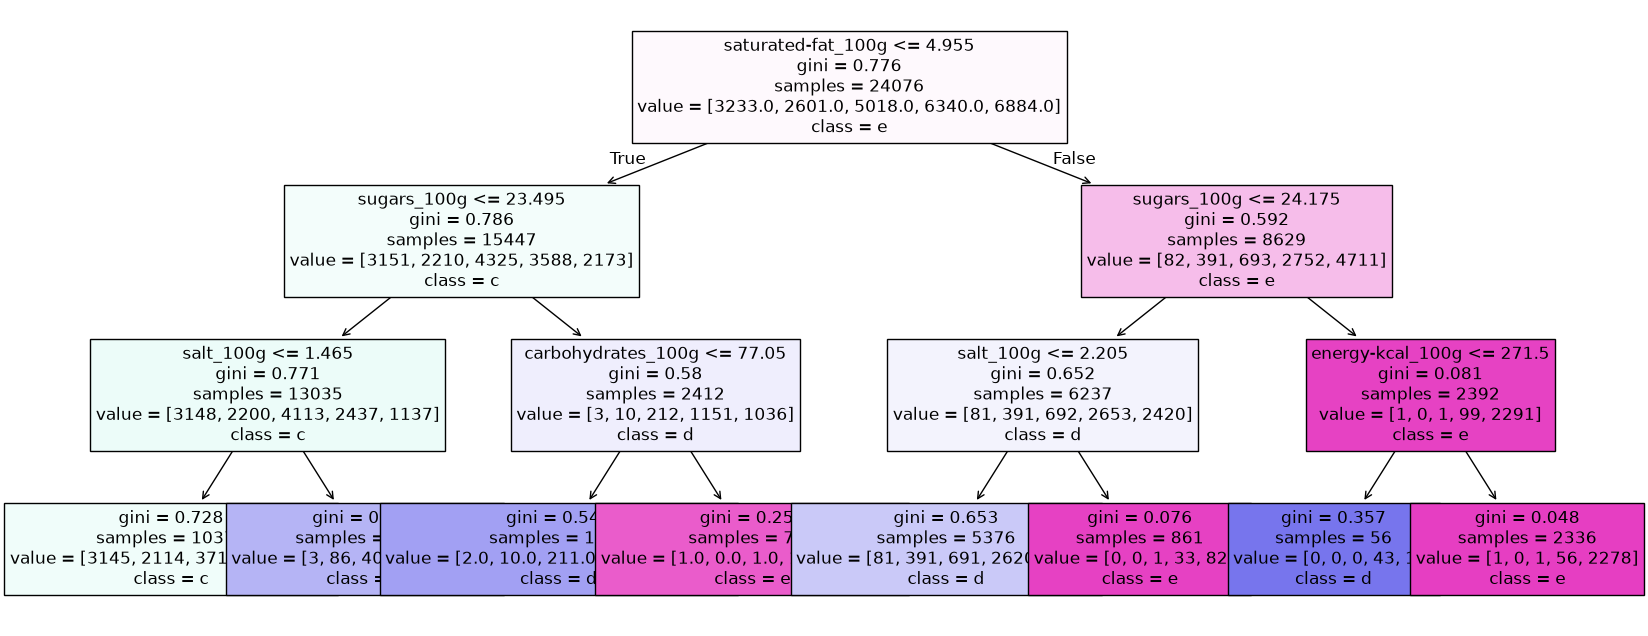

In [90]:
from sklearn.tree import export_text


tree_d3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train[NUTRIMENTS], y_train)
# print(export_text(tree_d3, feature_names=NUTRIMENTS))

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree_d3, feature_names=NUTRIMENTS, class_names=tree_d3.classes_, filled=True, ax=ax, fontsize=12)
plt.show()


### Lecture des baselines

- **`most_frequent` répond « e » pour tous les produits.** Son accuracy de 0,286 n'est que la part de la classe « e » dans le train : le modèle n'a rien appris. Le F1 macro (0,089) le montre, car il fait la moyenne des cinq classes à poids égal : « e » obtient un F1 d'environ 0,44 et les quatre autres classes 0. L'accuracy est **3,2 fois** plus élevée que le F1 macro. Sur des classes déséquilibrées, l'accuracy récompense le modèle qui prédit la classe majoritaire : c'est pour cela que **le F1 macro est notre métrique principale**.
- **`stratified`** tire les lettres au hasard en respectant les proportions. Son F1 macro de 0,200 correspond au hasard pur sur 5 classes (1/5), et son accuracy équilibrée de 0,200 aussi.
- **`tree_d3` ne prédit jamais « a » ni « b ».** Ses 8 feuilles ne disent que c, d ou e. Les produits a et b, environ 24 % du train, sont donc toujours mal classés, ce qui explique l'écart entre accuracy (0,521) et F1 macro (0,361). Avec seulement 8 feuilles, l'arbre se concentre sur les classes nombreuses. Ses découpes reprennent les composantes **défavorables** du Nutri-Score (graisses saturées, sucres, sel, énergie), mais pas les composantes **favorables** (fibres, protéines, fruits-légumes) : il ne peut pas distinguer un « a » d'un « c ».
- **`tree_d8` atteint un F1 macro de 0,685 ± 0,010.** **C'est la baseline à battre** pour la régression logistique et la random forest.

In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

import numpy as np

def add_derived_features(X: pd.DataFrame) -> pd.DataFrame:
    """Ajoute deux ratios et l'écart d'énergie (règle 4/4/9 du TP 9)."""
    X = X.copy()
    X["sat_fat_ratio"] = (X["saturated-fat_100g"] / X["fat_100g"].replace(0, np.nan)).fillna(0)
    X["sugar_ratio"] = (X["sugars_100g"] / X["carbohydrates_100g"].replace(0, np.nan)).fillna(0)
    energy_calc = 4 * X["carbohydrates_100g"] + 4 * X["proteins_100g"] + 9 * X["fat_100g"]
    X["energy_gap"] = X["energy-kcal_100g"] - energy_calc
    return X

DERIVEES = ["sat_fat_ratio", "sugar_ratio", "energy_gap"]


optional_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("nutr", StandardScaler(), NUTRIMENTS + DERIVEES),
    ("opt", optional_pipeline, OPTIONNELLES),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=80), CATEGORIELLES)
])

prep_pipeline = Pipeline([
    ("derived", FunctionTransformer(add_derived_features)),
    ("prep", preprocessor),
])

# print(X_train["pnns_groups_2"].value_counts().tail(10))

# display(add_derived_features(X_train))

X_prep = prep_pipeline.fit_transform(X_train)
print(X_prep.shape)

(24076, 66)


In [92]:
from sklearn.linear_model import LogisticRegression


logreg = Pipeline([("prep", prep_pipeline), ("model", LogisticRegression(max_iter=3000))])
results.append(evaluate_cv("logreg", logreg, X_train))

display(pd.DataFrame(results).set_index("model").round(3))

,f1_macro,f1_std,accuracy,balanced_accuracy,fit_time,score_time
model,,,,,,
most_frequent,0.089,0.000,0.286,0.200,0.009,0.018
stratified,0.200,0.007,0.226,0.200,0.008,0.021
tree_d3,0.361,0.001,0.521,0.417,0.034,0.022
tree_d8,0.685,0.010,0.735,0.687,0.064,0.030
logreg,0.767,0.008,0.805,0.766,0.821,0.038


In [93]:
from sklearn.ensemble import RandomForestClassifier


rnd_forest = Pipeline([("prep", prep_pipeline), ("model", RandomForestClassifier(random_state=42))])
results.append(evaluate_cv("rnd_forest", rnd_forest, X_train))

display(pd.DataFrame(results).set_index("model").round(3))

,f1_macro,f1_std,accuracy,balanced_accuracy,fit_time,score_time
model,,,,,,
most_frequent,0.089,0.000,0.286,0.200,0.009,0.018
stratified,0.200,0.007,0.226,0.200,0.008,0.021
tree_d3,0.361,0.001,0.521,0.417,0.034,0.022
tree_d8,0.685,0.010,0.735,0.687,0.064,0.030
logreg,0.767,0.008,0.805,0.766,0.821,0.038
rnd_forest,0.858,0.007,0.877,0.854,2.043,0.111


### Lecture : logistique et forêt

- **Les deux modèles battent la baseline** (arbre d8, 0,685) : la logistique atteint **0,767 ± 0,008** de F1 macro (+0,08) et la forêt **0,858 ± 0,007** (+0,17). Une partie du gain vient des features ajoutées (rayon, fibres, NOVA, features dérivées) : les arbres de l'étape 1 ne voyaient que les 7 nutriments obligatoires.
- **La forêt bat la logistique** car la logistique trace des frontières linéaires : elle additionne les effets de chaque feature et ne capte pas les combinaisons (« beaucoup de sucre *et* peu de fibres »). La forêt découpe par seuils successifs et capte ces interactions, proches des paliers du barème Nutri-Score.
- **Coût :** la forêt est environ 2,7 fois plus lente à ajuster (2,0 s contre 0,7 s par pli), un écart négligeable sur 24 000 produits.


In [94]:
X_test = df[df["split"] == "test"][FEATURES]

prep_pipeline.fit(X_train)
train_mean = prep_pipeline.transform(X_train)[:, 0].mean()
test_mean = prep_pipeline.transform(X_test)[:, 0].mean()

assert np.isclose(train_mean, 0, atol=1e-9), "le train standardisé doit être centré"
assert not np.isclose(test_mean, 0, atol=1e-9), "le test ne doit pas être centré : le préparateur l'aurait vu"
print(f"moyenne train : {train_mean:.2e} | moyenne test : {test_mean:.4f}")

moyenne train : -9.92e-17 | moyenne test : -0.0102


**Point de contrôle 3 :** après `fit` sur le train, la colonne standardisée a une moyenne nulle sur le train (≈ 1e-16) mais pas sur le test (≈ -0,010) : le préparateur n'a pas vu le test.